In [ ]:
Name Rohan Prakash Wayal
Roll no: 68
Problem Statement:- Implement and compare Support Vector Machine (SVM), Random Forest, and AdaBoost classifiers. Apply cross-validation and Grid Search for hyperparameter tuning, then compare performance before and after optimization.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
)

In [3]:
data = load_breast_cancer()
X = data.data
y = data.target

In [4]:
("Dataset:", data.DESCR.splitlines()[0])

('Dataset:', '.. _breast_cancer_dataset:')

In [5]:
("Number of samples:", X.shape[0])

('Number of samples:', 569)

In [6]:
("Number of features:", X.shape[1])

('Number of features:', 30)

In [7]:
("Classes:", data.target_names)

('Classes:', array(['malignant', 'benign'], dtype='<U9'))

In [8]:
("Class counts:", dict(zip(*np.unique(y, return_counts=True))))

('Class counts:', {np.int64(0): np.int64(212), np.int64(1): np.int64(357)})

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
("Training samples:", X_train.shape[0])

('Training samples:', 455)

In [10]:
("Testing samples:", X_test.shape[0])

('Testing samples:', 114)

In [11]:
baseline_models = {
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(probability=True, random_state=42))
    ]),
    "Random Forest": RandomForestClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42)
}
("Baseline models defined:", ", ".join(baseline_models.keys()))

('Baseline models defined:', 'SVM, Random Forest, AdaBoost')

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

baseline_cv_rows = []

for name, model in baseline_models.items():
    scores = cross_validate(
        model, X_train, y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )
    baseline_cv_rows.append({
        "Model": name,
        "CV Accuracy (%)": scores["test_accuracy"].mean() * 100,
        "CV Precision (%)": scores["test_precision"].mean() * 100,
        "CV Recall (%)": scores["test_recall"].mean() * 100,
        "CV F1 (%)": scores["test_f1"].mean() * 100,
        "CV ROC-AUC (%)": scores["test_roc_auc"].mean() * 100
    })

baseline_cv_df = pd.DataFrame(baseline_cv_rows).round(2)
baseline_cv_df

,Model,CV Accuracy (%),CV Precision (%),CV Recall (%),CV F1 (%),CV ROC-AUC (%)
0,SVM,96.92,97.28,97.89,97.56,99.56
1,Random Forest,96.26,97.55,96.49,96.99,98.96
2,AdaBoost,96.70,96.24,98.60,97.40,99.30


In [13]:
param_grids = {
    "SVM": {
        "model__C": [0.1, 1, 10],
        "model__kernel": ["linear", "rbf"],
        "model__gamma": ["scale", "auto"]
    },
    "Random Forest": {
        "n_estimators": [100, 200],
        "max_depth": [None, 10, 20],
        "min_samples_split": [2, 5]
    },
    "AdaBoost": {
        "n_estimators": [50, 100, 200],
        "learning_rate": [0.01, 0.1, 1.0]
    }
}

("Hyperparameter grids prepared for all three models.")

'Hyperparameter grids prepared for all three models.'

In [14]:
optimized_models = {}
grid_searches = {}
optimization_rows = []

for name, model in baseline_models.items():
    print(f"Running Grid Search for {name}...")

    search = GridSearchCV(
        estimator=model,
        param_grid=param_grids[name],
        scoring="accuracy",
        cv=cv,
        n_jobs=-1,
        refit=True
    )
    search.fit(X_train, y_train)

    grid_searches[name] = search
    optimized_models[name] = search.best_estimator_

    optimization_rows.append({
        "Model": name,
        "Best CV Accuracy (%)": search.best_score_ * 100,
        "Best Parameters": search.best_params_
    })

optimization_df = pd.DataFrame(optimization_rows)
optimization_df

Running Grid Search for SVM...
Running Grid Search for Random Forest...
Running Grid Search for AdaBoost...


,Model,Best CV Accuracy (%),Best Parameters
0,SVM,97.582418,"{'model__C': 0.1, 'model__gamma': 'scale', 'mo..."
1,Random Forest,96.263736,"{'max_depth': None, 'min_samples_split': 2, 'n..."
2,AdaBoost,98.021978,"{'learning_rate': 1.0, 'n_estimators': 100}"


In [15]:
def evaluate_classifier(model, X_eval, y_eval):
    y_pred = model.predict(X_eval)

    # Use probability scores when available; otherwise use decision scores
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_eval)[:, 1]
    elif hasattr(model, "decision_function"):
        y_score = model.decision_function(X_eval)
    else:
        y_score = y_pred

    return {
        "Accuracy (%)": accuracy_score(y_eval, y_pred) * 100,
        "Precision (%)": precision_score(y_eval, y_pred, zero_division=0) * 100,
        "Recall (%)": recall_score(y_eval, y_pred, zero_division=0) * 100,
        "F1-score (%)": f1_score(y_eval, y_pred, zero_division=0) * 100,
        "ROC-AUC (%)": roc_auc_score(y_eval, y_score) * 100
    }

test_rows = []

for name, model in baseline_models.items():
    metrics = evaluate_classifier(model.fit(X_train, y_train), X_test, y_test)
    test_rows.append({"Model": name, "Stage": "Before optimization", **metrics})

for name, model in optimized_models.items():
    metrics = evaluate_classifier(model, X_test, y_test)
    test_rows.append({"Model": name, "Stage": "After optimization", **metrics})

test_results_df = pd.DataFrame(test_rows).round(2)
test_results_df

,Model,Stage,Accuracy (%),Precision (%),Recall (%),F1-score (%),ROC-AUC (%)
0,SVM,Before optimization,98.25,98.61,98.61,98.61,99.50
1,Random Forest,Before optimization,95.61,95.89,97.22,96.55,99.37
2,AdaBoost,Before optimization,95.61,94.67,98.61,96.60,98.25
3,SVM,After optimization,98.25,98.61,98.61,98.61,99.37
4,Random Forest,After optimization,95.61,95.89,97.22,96.55,99.37
5,AdaBoost,After optimization,95.61,94.67,98.61,96.60,98.18


In [16]:
accuracy_comparison = test_results_df.pivot(
    index="Model", columns="Stage", values="Accuracy (%)"
)
accuracy_comparison["Change (percentage points)"] = (
    accuracy_comparison["After optimization"]
    - accuracy_comparison["Before optimization"]
)
accuracy_comparison.round(2)

Stage,After optimization,Before optimization,Change (percentage points)
Model,,,
AdaBoost,95.61,95.61,0.0
Random Forest,95.61,95.61,0.0
SVM,98.25,98.25,0.0


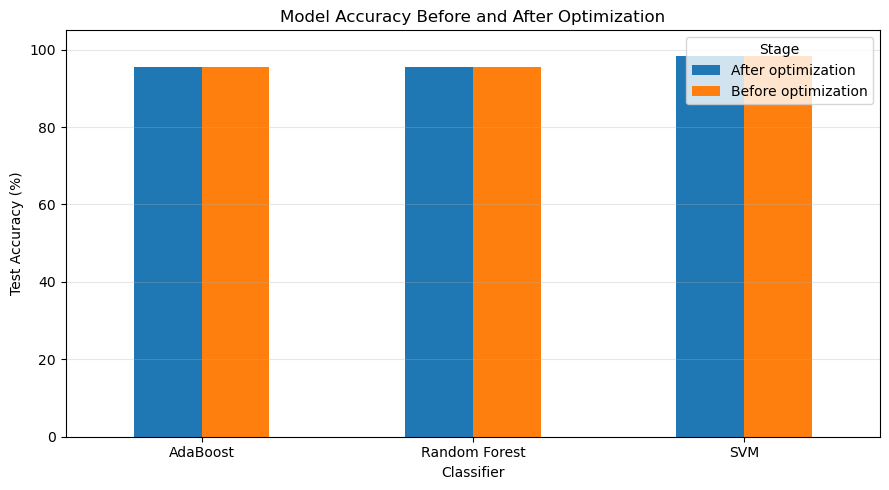

In [17]:
plot_df = test_results_df.pivot(
    index="Model", columns="Stage", values="Accuracy (%)"
)

ax = plot_df.plot(kind="bar", figsize=(9, 5))
ax.set_title("Model Accuracy Before and After Optimization")
ax.set_ylabel("Test Accuracy (%)")
ax.set_xlabel("Classifier")
ax.set_ylim(0, 105)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.legend(title="Stage")
plt.tight_layout()
plt.show()

In [18]:
best_model_name = max(
    grid_searches,
    key=lambda name: grid_searches[name].best_score_
)
best_search = grid_searches[best_model_name]

("Best model based on cross-validation:", best_model_name)

('Best model based on cross-validation:', 'AdaBoost')

In [19]:
(f"Best mean CV accuracy: {best_search.best_score_ * 100:.2f}%")

'Best mean CV accuracy: 98.02%'

In [20]:
("Best hyperparameters:", best_search.best_params_)

('Best hyperparameters:', {'learning_rate': 1.0, 'n_estimators': 100})